# 01 — Exploratory Data Analysis (EDA)

In this notebook we explore our raw synthetic student dataset (`data/raw/students_raw.csv`) before building features or models.

**Rules we follow from `PROJECT_CONTEXT.md`:**
- Reproducible everywhere with `SEED = 42`.
- Clean duplicates and impossible values, **but do NOT impute missing values here** (imputation belongs inside the `scikit-learn` `Pipeline`, fitted on training data only).
- Keep `gender` strictly for post-hoc bias auditing—never as a model feature.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ensure the repository root is on sys.path whether Jupyter starts in root or notebooks/.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import FIGURES_DIR, LOW_SCORE_THRESHOLD, RAW_DATA_PATH, SEED
from src.data_quality import clean_data, print_quality_report, report_data_quality

# Make sure the output folder for saved figures exists.
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Clean default styling for plots.
sns.set_theme(style="whitegrid")

## 1. Data Shape, Data Types, and First Rows

First, let's load the raw CSV and check how many rows and columns we have, what each column's data type is, and what one student's longitudinal assessment history looks like.

In [2]:
raw_df = pd.read_csv(RAW_DATA_PATH)

print(f"Raw dataset shape: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
print("\nColumn data types:")
print(raw_df.dtypes)

print("\nFirst 8 rows (one student across assessments 1 to 8):")
raw_df.head(8)

Raw dataset shape: 12060 rows x 9 columns

Column data types:
student_id                    object
grade_level                    int64
gender                        object
assessment_no                  int64
assessment_date               object
score                        float64
attendance_pct               float64
assignment_completion_pct    float64
late_submission_pct          float64
dtype: object

First 8 rows (one student across assessments 1 to 8):


,student_id,grade_level,gender,assessment_no,assessment_date,score,attendance_pct,assignment_completion_pct,late_submission_pct
0,STU_0001,8,Female,1,2025-09-01,73.0,85.9,67.2,18.1
1,STU_0001,8,Female,2,2025-09-18,45.3,87.5,72.8,18.5
2,STU_0001,8,Female,3,2025-10-06,54.2,78.3,77.9,19.9
3,STU_0001,8,Female,4,2025-10-23,55.0,85.4,75.3,11.7
4,STU_0001,8,Female,5,2025-11-10,60.6,86.0,94.5,10.4
5,STU_0001,8,Female,6,2025-11-27,63.9,95.5,81.0,12.5
6,STU_0001,8,Female,7,2025-12-15,55.5,92.6,86.5,13.8
7,STU_0001,8,Female,8,2026-01-01,45.8,91.4,85.0,11.3


## 2. Data Quality Checks (Before and After Cleaning)

Next, we run our audit functions from `src/data_quality.py` **before** and **after** cleaning.
`clean_data()` removes exact duplicate rows and replaces impossible values (scores or percentages outside `0–100`) with `NaN`. Notice that missing values remain `NaN` on purpose so our future `Pipeline` can impute them using training data only.

In [3]:
before_report = report_data_quality(raw_df)
print_quality_report(before_report, title="Before Cleaning (Raw Data)")

print("\n" + "-" * 55 + "\n")

clean_df = clean_data(raw_df)
after_report = report_data_quality(clean_df)
print_quality_report(after_report, title="After Cleaning (Duplicates Removed, Out-of-Range -> NaN)")

=== Before Cleaning (Raw Data) ===
Rows: 12060 | Columns: 9 | Unique students: 1500

Missing values:
  - attendance_pct: 363 (3.01%)
  - assignment_completion_pct: 241 (2.00%)

Duplicates:
  - Exact duplicate rows: 60
  - Duplicate (student_id, assessment_no) keys: 60

Out-of-range values (valid range: 0 to 100):
  - score: 12 total (< 0: 12, > 100: 0)
  - attendance_pct: 12 total (< 0: 0, > 100: 12)

-------------------------------------------------------

=== After Cleaning (Duplicates Removed, Out-of-Range -> NaN) ===
Rows: 12000 | Columns: 9 | Unique students: 1500

Missing values:
  - score: 12 (0.10%)
  - attendance_pct: 372 (3.10%)
  - assignment_completion_pct: 240 (2.00%)

Duplicates:
  - Exact duplicate rows: 0
  - Duplicate (student_id, assessment_no) keys: 0

Out-of-range values (valid range: 0 to 100):
  - None


## 3. Distribution of Scores and Share Below 50 (Class Imbalance)

Per `docs/problem_definition.md`, our binary target `low_next_score` equals `1` when the next assessment score is **below 50**. Here we inspect the overall score distribution and see how imbalanced the `< 50` class is.

Score summary statistics (cleaned valid scores):
count    11988.00
mean        64.89
std         17.41
min          0.00
25%         52.90
50%         65.00
75%         77.20
max        100.00
Name: score, dtype: float64

Share < 50 (all assessments 1..8): 20.11%
Share < 50 (target window 4..8):  21.24%


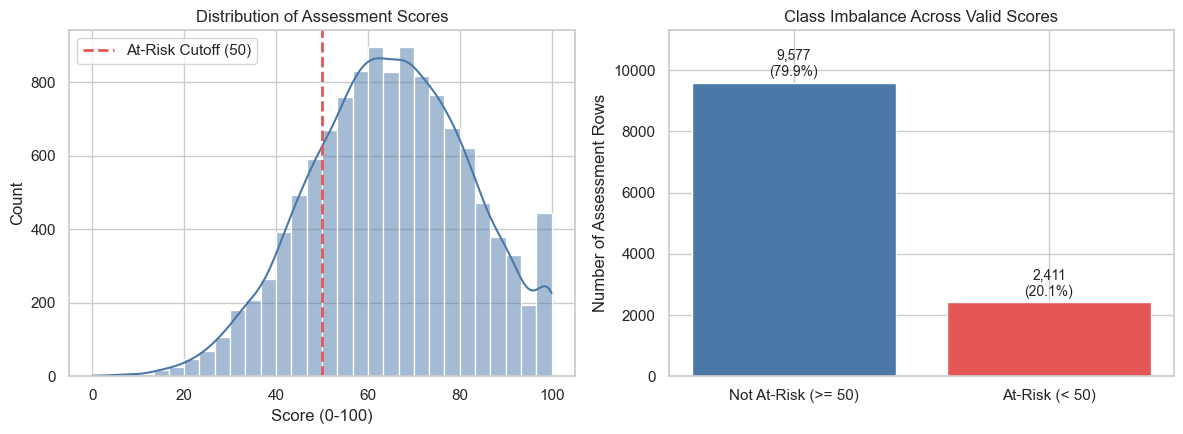

Saved figure: D:\student-risk-prediction\reports\figures\eda_score_distribution.png


In [4]:
valid_scores = clean_df["score"].dropna()
below_50_all = (valid_scores < LOW_SCORE_THRESHOLD).mean() * 100

# Assessments 4..8 correspond to the targets predicted from checkpoints k = 3..7.
target_window_scores = clean_df.loc[clean_df["assessment_no"] >= 4, "score"].dropna()
below_50_targets = (target_window_scores < LOW_SCORE_THRESHOLD).mean() * 100

print("Score summary statistics (cleaned valid scores):")
print(valid_scores.describe().round(2))
print(f"\nShare < {LOW_SCORE_THRESHOLD} (all assessments 1..8): {below_50_all:.2f}%")
print(f"Share < {LOW_SCORE_THRESHOLD} (target window 4..8):  {below_50_targets:.2f}%")

# Plot score distribution and class balance side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(valid_scores, bins=30, kde=True, color="#4C78A8", ax=axes[0])
axes[0].axvline(LOW_SCORE_THRESHOLD, color="#E45756", linestyle="--", linewidth=2,
                label=f"At-Risk Cutoff ({LOW_SCORE_THRESHOLD})")
axes[0].set_title("Distribution of Assessment Scores")
axes[0].set_xlabel("Score (0-100)")
axes[0].set_ylabel("Count")
axes[0].legend()

class_counts = (valid_scores < LOW_SCORE_THRESHOLD).value_counts().sort_index()
labels = [f"Not At-Risk (>= {LOW_SCORE_THRESHOLD})", f"At-Risk (< {LOW_SCORE_THRESHOLD})"]
colors = ["#4C78A8", "#E45756"]
bars = axes[1].bar(labels, [class_counts[False], class_counts[True]], color=colors)
axes[1].set_title("Class Imbalance Across Valid Scores")
axes[1].set_ylabel("Number of Assessment Rows")

for bar in bars:
    height = bar.get_height()
    pct = height / len(valid_scores) * 100
    axes[1].text(bar.get_x() + bar.get_width() / 2, height + 120,
                 f"{int(height):,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10)
axes[1].set_ylim(0, class_counts.max() * 1.18)

plt.tight_layout()
fig_path = FIGURES_DIR / "eda_score_distribution.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure: {fig_path}")

## 4. Attendance, Completion, Late Submissions, and Score Relationships

Do engagement signals (`attendance_pct`, `assignment_completion_pct`, `late_submission_pct`) relate to `score`? Let's check with a correlation heatmap and scatter plots. Notice we exclude `gender` because it is a sensitive attribute reserved strictly for post-hoc fairness auditing.

Correlation with score:
score                        1.000
assignment_completion_pct    0.647
attendance_pct               0.556
assessment_no                0.020
grade_level                 -0.008
late_submission_pct         -0.510
Name: score, dtype: float64


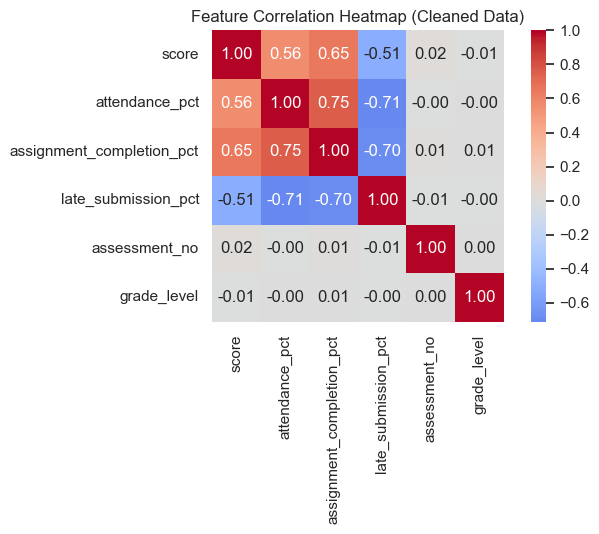

Saved figure: D:\student-risk-prediction\reports\figures\eda_correlation_heatmap.png


In [5]:
numeric_cols = [
    "score",
    "attendance_pct",
    "assignment_completion_pct",
    "late_submission_pct",
    "assessment_no",
    "grade_level",
]
corr_matrix = clean_df[numeric_cols].corr()
print("Correlation with score:")
print(corr_matrix["score"].sort_values(ascending=False).round(3))

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Feature Correlation Heatmap (Cleaned Data)")
plt.tight_layout()
heatmap_path = FIGURES_DIR / "eda_correlation_heatmap.png"
fig.savefig(heatmap_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure: {heatmap_path}")

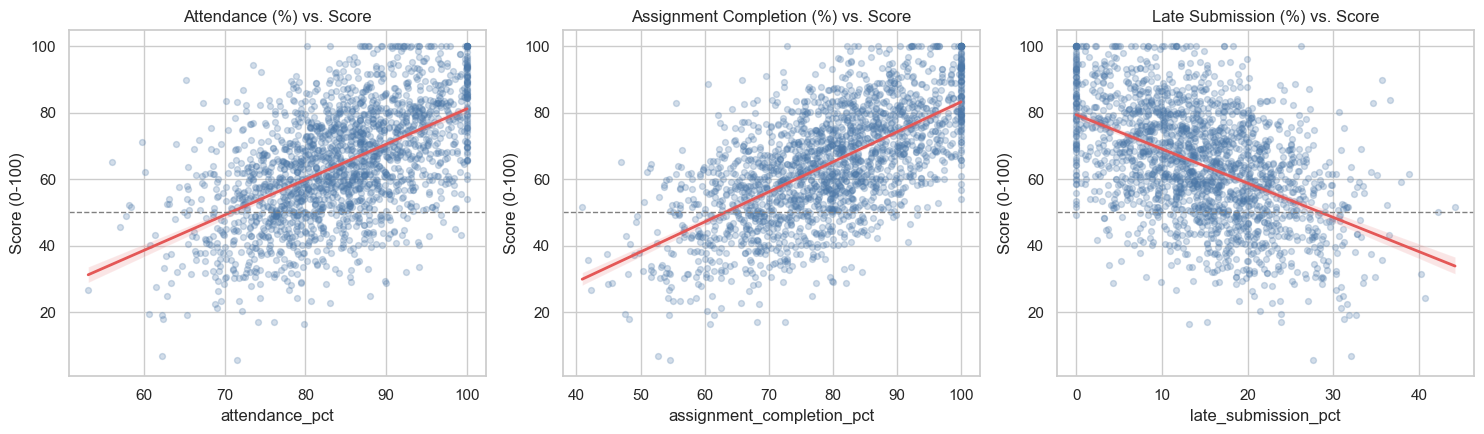

Saved figure: D:\student-risk-prediction\reports\figures\eda_score_relationships.png


In [6]:
# Sample 2,000 clean rows with SEED=42 so scatter plots remain readable and reproducible.
plot_sample = clean_df.dropna(
    subset=["score", "attendance_pct", "assignment_completion_pct", "late_submission_pct"]
).sample(n=2000, random_state=SEED)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
feature_pairs = [
    ("attendance_pct", "Attendance (%) vs. Score"),
    ("assignment_completion_pct", "Assignment Completion (%) vs. Score"),
    ("late_submission_pct", "Late Submission (%) vs. Score"),
]

for ax, (col, title) in zip(axes, feature_pairs):
    sns.regplot(
        data=plot_sample,
        x=col,
        y="score",
        scatter_kws={"alpha": 0.25, "s": 18, "color": "#4C78A8"},
        line_kws={"color": "#E45756", "linewidth": 2},
        ax=ax,
    )
    ax.axhline(LOW_SCORE_THRESHOLD, color="gray", linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel(col)
    ax.set_ylabel("Score (0-100)")

plt.tight_layout()
scatter_path = FIGURES_DIR / "eda_score_relationships.png"
fig.savefig(scatter_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure: {scatter_path}")

## 5. Score Trend Over `assessment_no` (Assessments 1 to 8)

Because our model makes sequential predictions after assessments `3` through `7`, let's inspect whether average scores, score spread, or the `< 50` rate shift across the term—and check how individual students change over time.

Score statistics by assessment_no:
 assessment_no  count  mean  median   std   q25   q75  pct_below_50
             1   1500 66.60    66.9 16.24 54.98 78.00         15.73
             2   1498 61.42    61.2 16.41 50.00 73.10         24.97
             3   1498 67.56    67.9 16.13 56.72 79.20         14.02
             4   1499 61.00    61.1 16.77 49.40 72.95         25.88
             5   1499 66.40    66.4 17.41 55.10 78.90         17.61
             6   1500 64.39    64.2 17.83 51.60 77.22         21.73
             7   1496 65.83    66.5 18.27 53.70 78.80         20.45
             8   1498 65.90    66.2 18.85 52.90 79.30         20.49

Student mean score change (Assessments 6-8 minus 1-3): std=10.62, min=-37.7, max=36.8


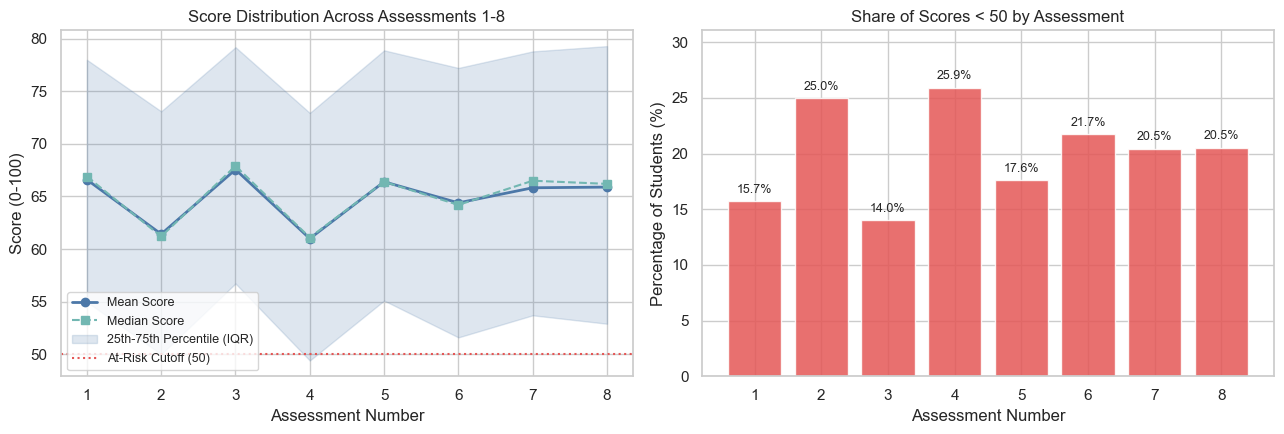

Saved figure: D:\student-risk-prediction\reports\figures\eda_score_trend.png


In [7]:
trend_stats = (
    clean_df.dropna(subset=["score"])
    .groupby("assessment_no")["score"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        q25=lambda s: s.quantile(0.25),
        q75=lambda s: s.quantile(0.75),
        pct_below_50=lambda s: (s < LOW_SCORE_THRESHOLD).mean() * 100,
    )
    .reset_index()
)
print("Score statistics by assessment_no:")
print(trend_stats.round(2).to_string(index=False))

# Measure individual student shifts between early (1-3) and late (6-8) assessments.
early_mean = clean_df[clean_df["assessment_no"] <= 3].groupby("student_id")["score"].mean()
late_mean = clean_df[clean_df["assessment_no"] >= 6].groupby("student_id")["score"].mean()
student_shift = (late_mean - early_mean).dropna()
print(f"\nStudent mean score change (Assessments 6-8 minus 1-3): "
      f"std={student_shift.std():.2f}, min={student_shift.min():.1f}, max={student_shift.max():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(trend_stats["assessment_no"], trend_stats["mean"], marker="o", linewidth=2,
             color="#4C78A8", label="Mean Score")
axes[0].plot(trend_stats["assessment_no"], trend_stats["median"], marker="s", linestyle="--",
             color="#72B7B2", label="Median Score")
axes[0].fill_between(trend_stats["assessment_no"], trend_stats["q25"], trend_stats["q75"],
                     color="#4C78A8", alpha=0.18, label="25th-75th Percentile (IQR)")
axes[0].axhline(LOW_SCORE_THRESHOLD, color="#E45756", linestyle=":", linewidth=1.5,
                label=f"At-Risk Cutoff ({LOW_SCORE_THRESHOLD})")
axes[0].set_title("Score Distribution Across Assessments 1-8")
axes[0].set_xlabel("Assessment Number")
axes[0].set_ylabel("Score (0-100)")
axes[0].set_xticks(range(1, 9))
axes[0].legend(loc="lower left", fontsize=9)

axes[1].bar(trend_stats["assessment_no"], trend_stats["pct_below_50"], color="#E45756", alpha=0.85)
axes[1].set_title(f"Share of Scores < {LOW_SCORE_THRESHOLD} by Assessment")
axes[1].set_xlabel("Assessment Number")
axes[1].set_ylabel("Percentage of Students (%)")
axes[1].set_xticks(range(1, 9))
for x, y in zip(trend_stats["assessment_no"], trend_stats["pct_below_50"]):
    axes[1].text(x, y + 0.5, f"{y:.1f}%", ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, trend_stats["pct_below_50"].max() * 1.2)

plt.tight_layout()
trend_path = FIGURES_DIR / "eda_score_trend.png"
fig.savefig(trend_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved figure: {trend_path}")

## 6. Leakage Thinking: What Information Is Unavailable at Prediction Time?

Per `docs/problem_definition.md`, we make a prediction **immediately after assessment `k` (`k = 3..7`) results are recorded** to predict `low_next_score` on assessment `k + 1` (~2–3 weeks in the future).

At prediction time `k`, all of the following information **does not exist yet or is forbidden** and must **never** leak into model features or training:

1. **Future assessment outcomes (`assessment_no > k`):**
   - `score` at `k + 1` (this is the target itself!) or any later assessment.
   - Future `attendance_pct`, `assignment_completion_pct`, `late_submission_pct`, or `assessment_date` from assessments `k + 1 .. 8`.
2. **Whole-term student averages or trends:**
   - Computing a student's overall average score or attendance across all `1..8` assessments and joining it onto checkpoint `k` leaks future semesters into early checkpoints.
   - Every rolling, lagged, cumulative, or slope feature built at checkpoint `k` must use **only rows with `assessment_no <= k`**.
3. **Same-student leakage across train/val/test splits:**
   - Each student contributes up to 5 checkpoint rows (`k = 3..7`). A naive random row split would put the same student's checkpoint `3` in training and checkpoint `4` in test, letting the model memorize that student.
   - We must split strictly by `student_id` (`GroupShuffleSplit` / student-level grouping).
4. **Pre-split imputation or feature scaling:**
   - Computing medians, means, or standard deviations across the entire dataset before splitting leaks validation/test distributions into training.
   - Imputation and scaling must live inside a `scikit-learn` `Pipeline`, fitted on the training set only.
5. **Protected/audit-only attributes (`gender`):**
   - Excluded from all feature engineering and modeling per `PROJECT_CONTEXT.md`; retained solely to verify the final model does not perform unfairly across demographic subgroups.

## 7. Summary of Findings

- **Dataset & Cleaning:** The raw file has `12,060` rows across `1,500` students (`8` assessments each plus `60` exact duplicate rows). `clean_data()` drops the `60` duplicates (leaving `12,000` clean rows) and converts `12` negative scores and `12` impossible attendance values (`> 100%`) into `NaN`, leaving missingness (`~3.1%` attendance, `~2.0%` assignment completion, `0.1%` score) to be imputed inside the training `Pipeline`.
- **Class Imbalance:** Around `20%` of scores fall below `50` (`~21%` in assessments `4..8`), confirming an imbalanced binary classification problem where **Recall** and **PR-AUC** are much more informative than raw accuracy.
- **Strong Behavioral Signals:** `assignment_completion_pct` (`r ≈ +0.65`) and `attendance_pct` (`r ≈ +0.56`) correlate positively with `score`, while `late_submission_pct` correlates negatively (`r ≈ -0.51`). `assessment_no` and `grade_level` show virtually zero direct linear correlation with `score`.
- **Temporal Dynamics:** While the cohort mean stays fairly stable across assessments `1..8`, individual students experience meaningful upward and downward trajectories over the term (seen in the wide `score` shift between assessments `1–3` and `6–8`), which makes historical score trends, recent lags, and engagement momentum valuable leak-free features to engineer next.